# Cherimoya / GPN-star: from a variant to a cell type to its evolutionary context

Most disease-associated variants sit in non-coding DNA, where three questions are hard to answer: *what does this variant do, in which cell type does it act, and does evolution care about that position?* This notebook tackles all three by combining two models.

[Cherimoya](https://github.com/jmschrei/cherimoya) is a compact (~0.6 M parameter)
convolutional sequence-to-function model in the BPNet / ChromBPNet family. **CATv1**
— the Cherimoya Accessibility aTlas — is a family of 1,518 per-experiment models
covering **1,149 ENCODE DNase-seq and 369 ATAC-seq experiments** on GRCh38, each
trained across five chromosome-held-out folds.

That makes it the widest biosample coverage in Chorus. The trade-off is that each model is specific
to one experiment, so picking the right one matters.

[GPN-star](https://www.nature.com/articles/s41586-026-11005-5) (Ye et al., 2026) is a phylogeny-aware genomic language model, designed to interpret DNA sequences and predict the functional impact of genetic variants.

**The plan.** We follow one well-studied variant, *SORT1* **rs12740374**, through four steps:

1. **Choose a model:** several Cherimoya experiments exist for the same cell line, so we compare them.
2. **Discover the cell type:** let Cherimoya scan the atlas for where the variant matters most.
3. **Measure the effect:** plot and score the change in predicted chromatin accessibility.
4. **Add evolutionary context:** overlay GPN-star LLRs to see how conserved the neighborhood is.

**Prerequisites**

```bash
chorus setup --oracle cherimoya      # ~7 GB env, ~3.5 min
chorus setup --oracle gpnstar        # downloads genome-wide annotations
chorus genome get hg38               # or symlink a GRCh38 FASTA to genomes/hg38.fa
```

> **Disk space:** the GPN-star annotations are genome-wide bigWig files of roughly 10–11 GB each
> (the four per-base LLR tracks used in Section 6 alone exceed 40 GB), so check your free space first.

**Acknowledgments**

We thank **Yun Song** and **Chengzhong Ye** for their assistance with integrating GPN-star into Chorus, and **Jacob Schreiber** for developing and integrating Cherimoya into Chorus.

**Using a custom model**

This notebook uses Cherimoya and GPN-star as examples. If you would like to use your own model instead, please refer to the relevant section of [`CONTRIBUTING.md`](../../CONTRIBUTING.md) for instructions on how to integrate a custom model into Chorus.

## 1. Setup

In [49]:
import chorus
import pandas as pd
from chorus.utils import get_genome

genome_path = get_genome()
cherimoya = chorus.create_oracle(
    "cherimoya",
    use_environment=True,
    reference_fasta=str(genome_path)
)

# Explore the available ATAC experiments
hits = cherimoya.search_tracks(query="ATAC")

print(f"Matching ATAC tracks: {len(hits)}")
display(hits.head(20))

2026-10-13 17:18:57,244 - chorus.core.base - INFO - Device: auto-detect (GPU if available, else CPU)
2026-10-13 17:19:00,017 - chorus.core.base - INFO - Using conda environment: chorus-cherimoya


Matching ATAC tracks: 369


,experiment_accession,annotation_accession,assay,biosample,biosample_classification,biosample_summary,biosample_term_id,assembly,perturbed,track_id,profile_pearson,count_pearson
2,ENCSR624CTU,ENCSR001QFX,ATAC,HG03520,cell line,NaN,EFO:0010885,GRCh38,False,ATAC:ENCSR624CTU,0.61352,0.70132
10,ENCSR329XFZ,ENCSR005GZQ,ATAC,dendritic cell,in vitro differentiated cells,treated with 100 ng/mL lipopolysaccharide for ...,CL:0000451,GRCh38,False,ATAC:ENCSR329XFZ,0.64765,0.74047
14,ENCSR552QUA,ENCSR006QRD,ATAC,posterior vena cava,tissue,female adult (47 years),UBERON:0001072,GRCh38,False,ATAC:ENCSR552QUA,0.83116,0.79634
17,ENCSR096BPX,ENCSR008JSY,ATAC,esophagus squamous epithelium,tissue,female adult (51 years),UBERON:0006920,GRCh38,False,ATAC:ENCSR096BPX,0.49615,0.82248
22,ENCSR899YEP,ENCSR012HQM,ATAC,heart left ventricle,tissue,male adult (61 years),UBERON:0002084,GRCh38,False,ATAC:ENCSR899YEP,0.61568,0.71312
27,ENCSR303PWB,ENCSR014REV,ATAC,esophagus mucosa,tissue,female adult (47 years),UBERON:0002469,GRCh38,False,ATAC:ENCSR303PWB,0.81292,0.79890
28,ENCSR305QTE,ENCSR015SXE,ATAC,natural killer cell,primary cell,male adult (47 years),CL:0000623,GRCh38,False,ATAC:ENCSR305QTE,0.70627,0.83002
29,ENCSR165FYY,ENCSR017RWH,ATAC,"central memory CD8-positive, alpha-beta T cell",primary cell,male adult (36 years),CL:0000907,GRCh38,False,ATAC:ENCSR165FYY,0.68535,0.74008
32,ENCSR452COS,ENCSR021MKA,ATAC,"naive thymus-derived CD4-positive, alpha-beta ...",primary cell,male adult (50 years),CL:0000895,GRCh38,False,ATAC:ENCSR452COS,0.75944,0.80752
45,ENCSR222SCA,ENCSR026FFL,ATAC,dendritic cell,in vitro differentiated cells,treated with 100 ng/mL lipopolysaccharide for ...,CL:0000451,GRCh38,False,ATAC:ENCSR222SCA,0.61486,0.75969


The table above lists the ATAC experiments available in the atlas (369 in total; only the first 20 are displayed).
`profile_pearson` and `count_pearson` are the model's fold-0 validation metrics (agreement between predicted and
observed profile shape, and between predicted and observed total counts, respectively), so
you can see up front how well a given experiment was learned. They vary a lot across
the atlas, so it's worth checking before trusting a track.

## 2. Loading a model

Track ids are **`ASSAY:ENCSR`** — the ENCODE *experiment* accession — not
`ASSAY:cell_type`. That is a deliberate departure from ChromBPNet, and the reason is
worth understanding before you pick a model.

The 1,518 experiments collapse into only 492 `(assay, biosample)` pairs, and 162 of
those pairs hold more than one experiment — up to 83 for `DNase-seq / head of caudate
nucleus`. It is not confined to obscure tissues either: **K562 alone has four ATAC
experiments**. A biosample-keyed scheme would leave 1,188 of the 1,518 models
unaddressable.

Thanks to Chorus interface, we can cycle over the four ATAC:K562
Cherimoya models, trying to understand whether predictions change in different experiments.

In [50]:
# Search for K562 tracks for ATAC-seq
ATAC_tracks = cherimoya.search_tracks("ATAC")
hits = ATAC_tracks[
    ATAC_tracks["biosample"] == "K562"
]

accessions = (
    hits["experiment_accession"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

print(f"Found {len(accessions)} ATAC experiments for K562")
display(hits)

# Load each experiment-specific model and predict over the same region.
region = ("chr1", 109273911, 109276025)
results = {}

for accession in accessions:
    track_id = f"ATAC:{accession}"

    try:
        cherimoya.load_pretrained_model(
            assay="ATAC",
            encode_id=accession,
        )

        prediction = cherimoya.predict(
            region,
            [track_id],
        )

        results[track_id] = prediction
        print(f"Completed {track_id}")

    except Exception as exc:
        print(f"Skipping {track_id}: {exc}")

Found 4 ATAC experiments for K562


,experiment_accession,annotation_accession,assay,biosample,biosample_classification,biosample_summary,biosample_term_id,assembly,perturbed,track_id,profile_pearson,count_pearson
80,ENCSR859USB,ENCSR049OFB,ATAC,K562,cell line,NaN,EFO:0002067,GRCh38,False,ATAC:ENCSR859USB,0.63016,0.83833
727,ENCSR868FGK,ENCSR467RSV,ATAC,K562,cell line,NaN,EFO:0002067,GRCh38,False,ATAC:ENCSR868FGK,0.85590,0.74361
1168,ENCSR483RKN,ENCSR780QKO,ATAC,K562,cell line,NaN,EFO:0002067,GRCh38,False,ATAC:ENCSR483RKN,0.67590,0.78842
1423,ENCSR956DNB,ENCSR939RXI,ATAC,K562,cell line,NaN,EFO:0002067,GRCh38,False,ATAC:ENCSR956DNB,0.63090,0.79979


2026-10-13 17:19:03,969 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/programmable-genomics/CATv1/resolve/main/models/ENCSR859USB/cherimoya.fold_0.torch "HTTP/1.1 302 Found"
2026-10-13 17:19:03,970 - chorus.oracles.cherimoya - INFO - Loading Cherimoya ATAC:ENCSR859USB (K562, fold 0)...
2026-10-13 17:19:06,482 - chorus.oracles.cherimoya - INFO - Cherimoya model loaded in environment (cuda).
2026-10-13 17:19:09,552 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/programmable-genomics/CATv1/resolve/main/models/ENCSR868FGK/cherimoya.fold_0.torch "HTTP/1.1 302 Found"
2026-10-13 17:19:09,553 - chorus.oracles.cherimoya - INFO - Loading Cherimoya ATAC:ENCSR868FGK (K562, fold 0)...


Completed ATAC:ENCSR859USB


2026-10-13 17:19:12,024 - chorus.oracles.cherimoya - INFO - Cherimoya model loaded in environment (cuda).
2026-10-13 17:19:15,179 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/programmable-genomics/CATv1/resolve/main/models/ENCSR483RKN/cherimoya.fold_0.torch "HTTP/1.1 302 Found"
2026-10-13 17:19:15,180 - chorus.oracles.cherimoya - INFO - Loading Cherimoya ATAC:ENCSR483RKN (K562, fold 0)...


Completed ATAC:ENCSR868FGK


2026-10-13 17:19:17,552 - chorus.oracles.cherimoya - INFO - Cherimoya model loaded in environment (cuda).
2026-10-13 17:19:20,839 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/programmable-genomics/CATv1/resolve/main/models/ENCSR956DNB/cherimoya.fold_0.torch "HTTP/1.1 302 Found"
2026-10-13 17:19:20,840 - chorus.oracles.cherimoya - INFO - Loading Cherimoya ATAC:ENCSR956DNB (K562, fold 0)...


Completed ATAC:ENCSR483RKN


2026-10-13 17:19:23,187 - chorus.oracles.cherimoya - INFO - Cherimoya model loaded in environment (cuda).


Completed ATAC:ENCSR956DNB


In [59]:
import pandas as pd

region = ("chr1", 109273911, 109276025)
stats = []
for track_id, pred in results.items():
    mean_scores = pred.score_region(chrom=region[0],
        start=region[1], end=region[2], scoring_strategy="mean")
    max_scores = pred.score_region(chrom=region[0],
        start=region[1], end=region[2], scoring_strategy="max")
    stats.append({"track": track_id, "mean_signal": mean_scores[track_id], "max_scores": max_scores[track_id]})
summary = pd.DataFrame(stats).sort_values("mean_signal", ascending=False)
display(summary)


,track,mean_signal,max_scores
1,ATAC:ENCSR868FGK,0.326885,22.169004
2,ATAC:ENCSR483RKN,0.051926,3.808049
0,ATAC:ENCSR859USB,0.026822,1.695264
3,ATAC:ENCSR956DNB,0.024000,1.698851


Even when assay (ATAC-seq) and biosample (K562) coincide, predicted signals **can vary substantially across experiments**. For example, ATAC:ENCSR868FGK shows a much higher mean signal than the other experiments. 

## 3. Discovering cell type

Let's say a clinician has just discovered a variant and would like to know in which cell types it has the strongest effects. Luckily for us, the Cherimoya collection spans ~1,500 different ENCODE experiments, so `discover_variant_effects` can score the variant against the atlas and return the tracks with the largest predicted effects, without us having to choose tracks by hand.

Here we use the *SORT1* variant as an example.

*rs12740374* is a G>T substitution which has been connected to [higher expression of the SORT1](https://www.nature.com/articles/nature09266) gene in liver cells.

This overexpression is attributed to a newly formed **C/EBP binding site**, located 118 kb upstream of the *SORT1* TSS.
So let's see whether Cherimoya predicts an increase in chromatin accessibility at the variant locus.

> ⚠️ **Warning: the next cell is slow.** It runs Cherimoya models across the whole atlas (one representative experiment
> per biosample, i.e. hundreds of models in CATv1), loading each one in turn. In our run this took roughly
> 9–15 seconds per model on a GPU, so expect **tens of minutes to over an hour**, and longer on CPU.
> Let it finish rather than interrupting it. If you only want to follow the rest of the tutorial, you can skip this
> cell: nothing after it depends on its output.

In [ ]:
import pandas as pd
from chorus.analysis import discover_variant_effects, get_pertrack_normalizer

# SORT1 variant values
chrom = "chr1"
position = 109_274_968
ref_base = "G"
alt_base = "T"

# Per-track calibration
normalizer = get_pertrack_normalizer("cherimoya")

# Discover the strongest predicted effects without manually choosing tracks
# Here we are using the default ranking metric, i.e. `alt_per_abs_effect`
# which rewards both effect magnitude and absolute final activity
discovery = discover_variant_effects(
    oracle=cherimoya,
    oracle_name="cherimoya",
    variant_position=f"{chrom}:{position}",
    alleles=[ref_base, alt_base],
    top_n_per_layer=100,        # retain top 100
    top_n_cell_types=100,       # retain top 100
    normalizer=normalizer
)

print("Tracks scored:", discovery["total_tracks_scored"])
print("Tracks selected:", discovery["selected_tracks"])

# Convert report to dataframe
report = pd.DataFrame(discovery["cell_type_ranking"])

# Save for later inspection
report.to_csv(
    "cherimoya_discovery_ranking.csv",
    index=False
)

# Inspect the top 10 cell types
display(report.head(10))

In [18]:
display(report.head(10))

,cell_type,best_layer,best_track,best_effect,best_abs_effect,best_ref_value,best_alt_value,ranking_metric,ranking_score,low_baseline_warning,effect_pctile,effect_exceedance,n_tracks,layers_affected
0,left lobe of liver,chromatin_accessibility,ATAC:left lobe of liver,0.817672,0.817672,2436.055375,4294.453736,alt_x_abs_effect,3511.452434,False,0.9947,NaN,1,[chromatin_accessibility]
1,lower lobe of left lung,chromatin_accessibility,ATAC:lower lobe of left lung,1.008528,1.008528,1337.683627,2692.239672,alt_x_abs_effect,2715.197946,False,0.9985,NaN,1,[chromatin_accessibility]
2,HCEC 1CT,chromatin_accessibility,DNASE:HCEC 1CT,1.919168,1.919168,322.254393,1221.564066,alt_x_abs_effect,2344.386894,False,0.9985,NaN,1,[chromatin_accessibility]
3,skeletal muscle myoblast,chromatin_accessibility,DNASE:skeletal muscle myoblast,1.946526,1.946526,304.584663,1176.861611,alt_x_abs_effect,2290.791728,False,0.9973,NaN,1,[chromatin_accessibility]
4,A549,chromatin_accessibility,ATAC:A549,1.074790,1.074790,883.807349,1862.772121,alt_x_abs_effect,2002.089225,False,0.9982,NaN,1,[chromatin_accessibility]
5,HT-29,chromatin_accessibility,DNASE:HT-29,0.934842,0.934842,1118.127497,2138.415114,alt_x_abs_effect,1999.080332,False,0.9953,NaN,1,[chromatin_accessibility]
6,sciatic nerve,chromatin_accessibility,ATAC:sciatic nerve,1.672573,1.672573,359.620326,1148.594835,alt_x_abs_effect,1921.108554,False,1.0000,1.401602,1,[chromatin_accessibility]
7,GM23248,chromatin_accessibility,DNASE:GM23248,1.482074,1.482074,455.735707,1274.891183,alt_x_abs_effect,1889.482827,False,0.9937,NaN,1,[chromatin_accessibility]
8,upper lobe of right lung,chromatin_accessibility,ATAC:upper lobe of right lung,0.980846,0.980846,875.470357,1728.821817,alt_x_abs_effect,1695.708371,False,0.9997,NaN,1,[chromatin_accessibility]
9,CD1c-positive myeloid dendritic cell,chromatin_accessibility,DNASE:CD1c-positive myeloid dendritic cell,1.014820,1.014820,788.121794,1593.539832,alt_x_abs_effect,1617.156484,False,0.9977,NaN,1,[chromatin_accessibility]


The top hit is **left lobe of liver**, so let's further inspect the variant effect using this specific model.

## 4. Variant Effect Prediction

First we need to search for the accession number of the Cherimoya model corresponding to `ATAC:left lobe of liver`. To do this, we will use `search_track()` method on **Cherimoya** oracle.

In [60]:
# Search for left lobe of liver track
liver_tracks = cherimoya.search_tracks("left lobe of liver")

# Retain only the ATAC one
ATAC_liver_tracks = liver_tracks[
    liver_tracks["assay"] == "ATAC"
]
display(ATAC_liver_tracks)

# Take the accessions
accessions = (
    ATAC_liver_tracks["experiment_accession"]
    .dropna()
    .drop_duplicates()
    .tolist()
)
print(f"Selected accessions: {accessions}")

,experiment_accession,annotation_accession,assay,biosample,biosample_classification,biosample_summary,biosample_term_id,assembly,perturbed,track_id,profile_pearson,count_pearson
1130,ENCSR624ODL,ENCSR764RSP,ATAC,left lobe of liver,tissue,female adult (61 years),UBERON:0001115,GRCh38,False,ATAC:ENCSR624ODL,0.86037,0.76033


Selected accessions: ['ENCSR624ODL']


Now we apply the variant to each of the four K562 models. For every experiment, the next cell reloads the model and calls `predict_variant_effect`, which predicts the accessibility profile around *rs12740374* (G>T) with both the reference (`G`) and the alternative (`T`) allele.

In [61]:
# SORT1 variant values
chrom = "chr1"
position = 109_274_968
ref_base = "G"
alt_base = "T"

# Empty dict to collect results
variant_results = {}

for accession in accessions:
    track_id = f"ATAC:{accession}"

    try:
        cherimoya.load_pretrained_model(
            assay="ATAC",
            encode_id=accession,
        )

        result = cherimoya.predict_variant_effect(
            genomic_region=f"{chrom}:{position}-{position}",
            variant_position=f"{chrom}:{position}",
            alleles=[ref_base, alt_base],
            assay_ids=None,
        )

        variant_results[track_id] = result
        print(f"Completed {track_id}")

    except Exception as exc:
        print(f"Skipping {track_id}: {exc}")


2026-10-13 17:26:34,732 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/programmable-genomics/CATv1/resolve/main/models/ENCSR624ODL/cherimoya.fold_0.torch "HTTP/1.1 302 Found"
2026-10-13 17:26:34,733 - chorus.oracles.cherimoya - INFO - Loading Cherimoya ATAC:ENCSR624ODL (left lobe of liver, fold 0)...
2026-10-13 17:26:37,098 - chorus.oracles.cherimoya - INFO - Cherimoya model loaded in environment (cuda).


Completed ATAC:ENCSR624ODL


In [62]:
from chorus.analysis.normalization import get_pertrack_normalizer
from chorus.analysis.scorers import score_variant_multilayer

normalizer = get_pertrack_normalizer("cherimoya")
row = score_variant_multilayer(result)["alt_1"][cherimoya.track_id]

effect = normalizer.effect_percentile("cherimoya", cherimoya.track_id, abs(row["raw_score"]))
activity = normalizer.activity_percentile("cherimoya", cherimoya.track_id, row["ref_value"])

print(f"layer            : {row['layer']}")
print(f"ref / alt        : {row['ref_value']:.1f} / {row['alt_value']:.1f}")
print(f"raw log2FC       : {row['raw_score']:+.4f}")
print(f"effect percentile: {effect:.3f}")
print(f"activity pctile  : {activity:.3f}")

2026-10-13 17:26:44,951 - chorus.analysis.normalization - INFO - Loaded per-track CDFs for 'cherimoya': 1518 tracks, CDFs: effect_cdfs, summary_cdfs, perbin_cdfs


layer            : chromatin_accessibility
ref / alt        : 2436.1 / 4294.5
raw log2FC       : +0.8177
effect percentile: 0.995
activity pctile  : 0.933


How to read the printout:

* **ref / alt** — predicted accessibility with the reference and alternative allele.
* **raw log2FC** — log2 fold change between the two; positive values mean the alternative allele increases accessibility.
* **effect percentile** — how the size of this effect ranks against the background distribution of variant effects for the same track, so values close to 1 indicate an unusually large effect.
* **activity percentile** — how the reference accessibility at this locus ranks against the track's background, i.e. how active the locus already is.

### Plotting the predictions

Numbers are great, but nothing beats *seeing* the tracks. We will use the shared oracle plotting method built on **coolbox**, which stacks several predictions in one figure and lines them up with genomic annotations such as gene models.

**How to read the figure:**

* Each of the four K562 experiments appears **twice in the same color**: once with the reference allele (`G`) and once with the alternative allele (`T`).
* The window is the 1,000 bp output region centered on the variant (`chr1:109,274,968`).
* The bottom track shows the GENCODE gene models, so you can see where the locus sits relative to *SORT1*.

Compare each reference/alternative pair at the center of the window to see how the G>T substitution shifts predicted accessibility.

2026-10-13 17:26:47,699 - chorus.utils.annotations - INFO - Annotation file already exists: /storage_1/lruggeri/projects/chorus-article/reproduce/chorus/annotations/gencode.v48.basic.annotation.gtf
2026-10-13 17:26:48,416 - chorus.analysis.normalization - INFO - Loaded per-track CDFs for 'cherimoya': 1518 tracks, CDFs: effect_cdfs, summary_cdfs, perbin_cdfs
2026-10-13 17:26:49,082 - chorus.analysis.normalization - INFO - Loaded per-track CDFs for 'cherimoya': 1518 tracks, CDFs: effect_cdfs, summary_cdfs, perbin_cdfs


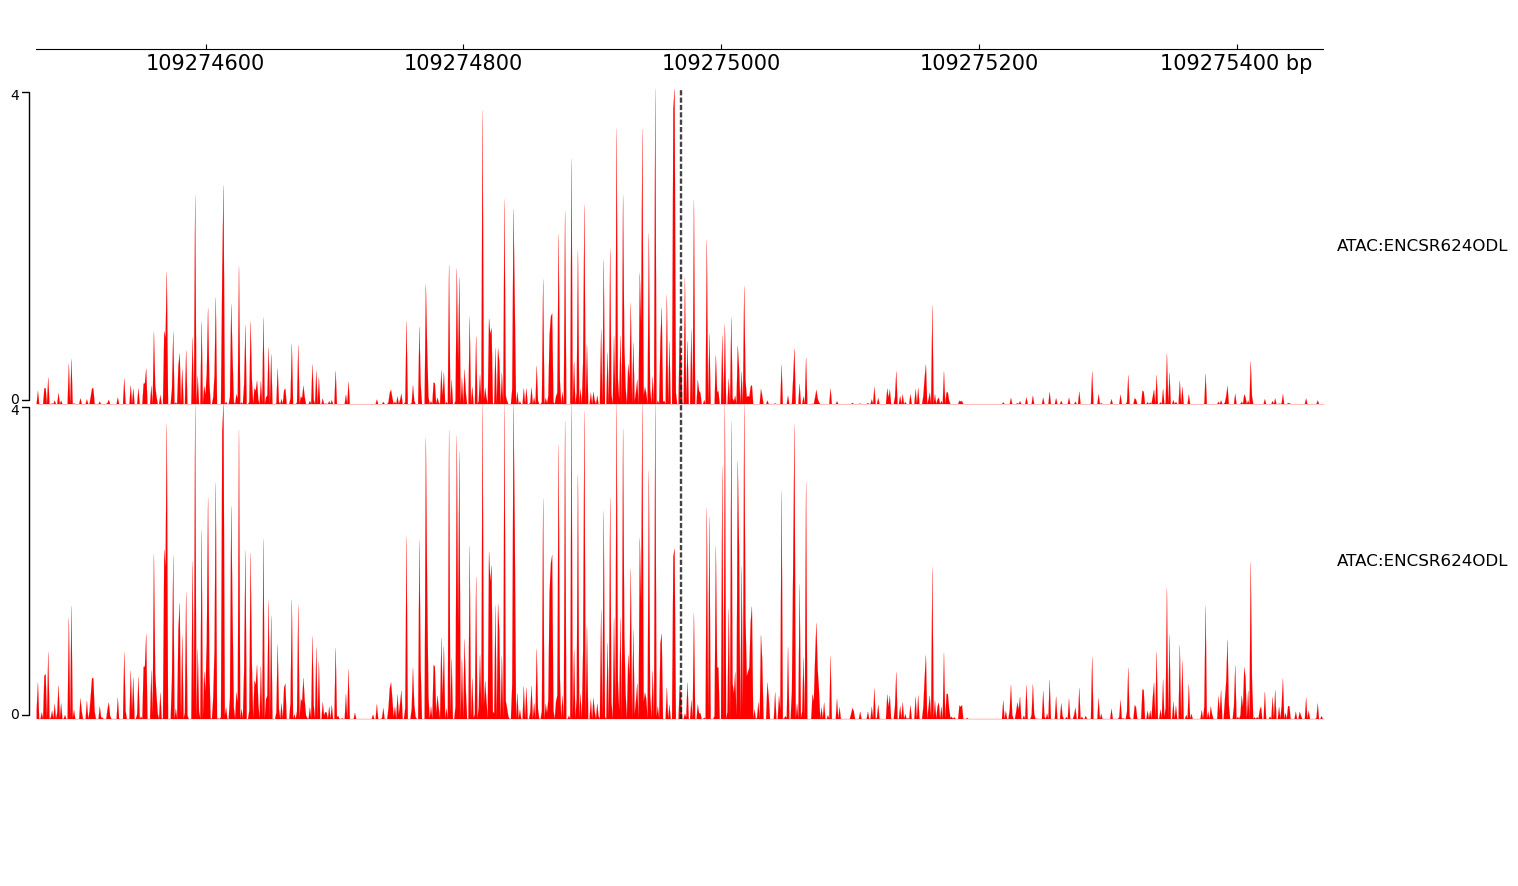

In [63]:
from coolbox.api import *
from chorus.utils import download_gencode, make_gene_track
from functools import reduce

# Open gtf path
gtf_path = download_gencode()

# For plotting
colors = ["red", "green"]

atac_tracks = [
    variant_results[f"ATAC:{acc}"]["predictions"][condition][f"ATAC:{acc}"].get_coolbox_representation(
        add_xaxis=False,
        add_vlines=False,
        override_params={"color": colors[i]}
    ) + Vlines(f"{chrom}:{position}")   # add variant locus
    for i, acc in enumerate(accessions)
    for condition in ["reference", "alt_1"]
]

frame = (
    XAxis()
    + reduce(lambda a, b: a + b, atac_tracks)
    + make_gene_track(gtf_path)
)
frame.plot(f"{chrom}:109_274_468-109_275_468") 

Plot shows that in both experiments G>T substitution substatially **increase chromatin accessibility**.

Looking at the raw signal could be misleading, so Chorus provide different methods to look at the variant effect.
Here we construct a table for the second cherimoya **ATAC:HepG2** model (**ENCSR042AWH**), looking at how the variant increases chromatin accessibility in that locus.

## 5. GPN-star: does evolution agree?

In [64]:
import numpy as np
import pyBigWig

from coolbox.core.track.base import Track

# Helper class for plotting GPNStarLLRs
class GPNStarLLR(Track):
    """Four-row, per-nucleotide GPN-Star LLR heatmap."""

    bases = ("A", "C", "G", "T")

    def __init__(self, bigwig_paths, properties_dict=None, base_titles=None, **kwargs):
        super().__init__(properties_dict=properties_dict or {}, **kwargs)
        self.base_titles = base_titles or {b: b for b in self.bases}
        self.bw = {b: pyBigWig.open(bigwig_paths[b]) for b in self.bases}

    def plot_label(self):
        if getattr(self, "label_ax", None) is None:
            return
        n = len(self.bases)
        for i, base in enumerate(self.bases):
            self.label_ax.text(
                0.15, 1 - (i + 0.5) / n,          # row 0 (A) is at the top
                self.base_titles[base],
                transform=self.label_ax.transAxes,
                horizontalalignment="left",
                verticalalignment="center",
                size="large",
            )

    def plot(self, ax, gr, **kwargs):
        chrom = gr.chrom
        start, end = int(gr.start), int(gr.end)

        # One value per genomic base, for each possible nucleotide.
        rows = []
        for base in self.bases:
            values = np.asarray(
                self.bw[base].values(chrom, start, end, numpy=True),
                dtype=float,
            )
            rows.append(-values)  # UCSC displays -LLR

        matrix = np.vstack(rows)
        matrix = np.ma.masked_invalid(matrix)

        ax.imshow(
            matrix,
            extent=(start, end, len(self.bases), 0),
            aspect="auto",
            interpolation="nearest",
            cmap="Greys",
            vmin=0,
            vmax=10,
        )

        ax.set_yticks([0.5, 1.5, 2.5, 3.5])
        ax.set_yticklabels(["A", "C", "G", "T"])
        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            labelsize=9,
            length=0,
            pad=3,
        )
        ax.set_ylabel("Base", labelpad=5)

        self.plot_label()


All *annotations* in Chorus are managed by `AnnotationStore` object.

```python
from chorus.utils import get_annotation_store

AnnotationStore = get_annotation_store()
```

With `AnnotationStore`, you can:

1. List all downloaded/downloadable annotations 
2. Download an annotation locally
3. Load an annotation
4. Add your *custom* annotation

In [65]:
from chorus.utils import get_annotation_store

# Annotation Store manages all Chorus Annotations
AnnotationStore = get_annotation_store()

# List all annotations found locally
AnnotationStore.list_annotations()

[AnnotationEntry(id='gpn_star', origin='conservation', description='GPN-Star entropy conservation score, vertebrate-alignment model (hg38)', genome_build='hg38', format='bigwig', downloaded=True, path=PosixPath('/storage_1/lruggeri/projects/chorus-article/reproduce/chorus/downloads/gpn_star/entropy.bw'), size_bytes=9897991293, size_note='~9.9 GB', source={'kind': 'hf', 'hf_repo': 'songlab/gpn-star-scores', 'hf_revision': 'a7b13bbf0d2338d74a7e5f0f8466e41ac0722f50', 'hf_filename': 'bigwig/gpn-star-hg38-v100-200m/entropy.bw', 'local_subdir': 'gpn_star', 'local_filename': 'entropy.bw', 'size_note': '~9.9 GB'}, verified_genome_build=None, warning=None),
 AnnotationEntry(id='gpn_star_llr_a', origin='conservation', description='GPN-Star calibrated log-likelihood ratio, base A, vertebrate-alignment model (hg38)', genome_build='hg38', format='bigwig', downloaded=True, path=PosixPath('/storage_1/lruggeri/projects/chorus-article/reproduce/chorus/downloads/gpn_star_llr/llr_A.bw'), size_bytes=11008

So the **GPN-star** annotations are already downloaded. You can also see that Chorus supports *phastCons* and *phyloP* annotations, together with *gencode* annotations.

Let's add **GPN-star LLRs** on top of the earlier predictions to see whether the variant falls into a highly conserved region.
The heatmap shows, for each position, the negative LLR of substituting the reference base with each of the four nucleotides: darker cells mean that the model finds that substitution less likely, i.e. the position is more constrained.

> **Note:** if the per-base LLR files are not on disk yet, the next cell will download them (over 40 GB in total).

In [66]:
# Cycle over basis to get all paths to GPN-star LLRs
llr_paths = {
    base.upper() : str(AnnotationStore.download_annotation(f"gpn_star_llr_{base}"))
    for base in ["a", "c", "g", "t"]
}

# Create the track object
gpn_track = GPNStarLLR(
    llr_paths,
    base_titles={"A": "A (-LLR)", "C": "C (-LLR)", "G": "G (-LLR)", "T": "T (-LLR)"},
    height=3,
)

2026-10-13 17:27:05,223 - chorus.analysis.normalization - INFO - Loaded per-track CDFs for 'cherimoya': 1518 tracks, CDFs: effect_cdfs, summary_cdfs, perbin_cdfs
2026-10-13 17:27:05,853 - chorus.analysis.normalization - INFO - Loaded per-track CDFs for 'cherimoya': 1518 tracks, CDFs: effect_cdfs, summary_cdfs, perbin_cdfs


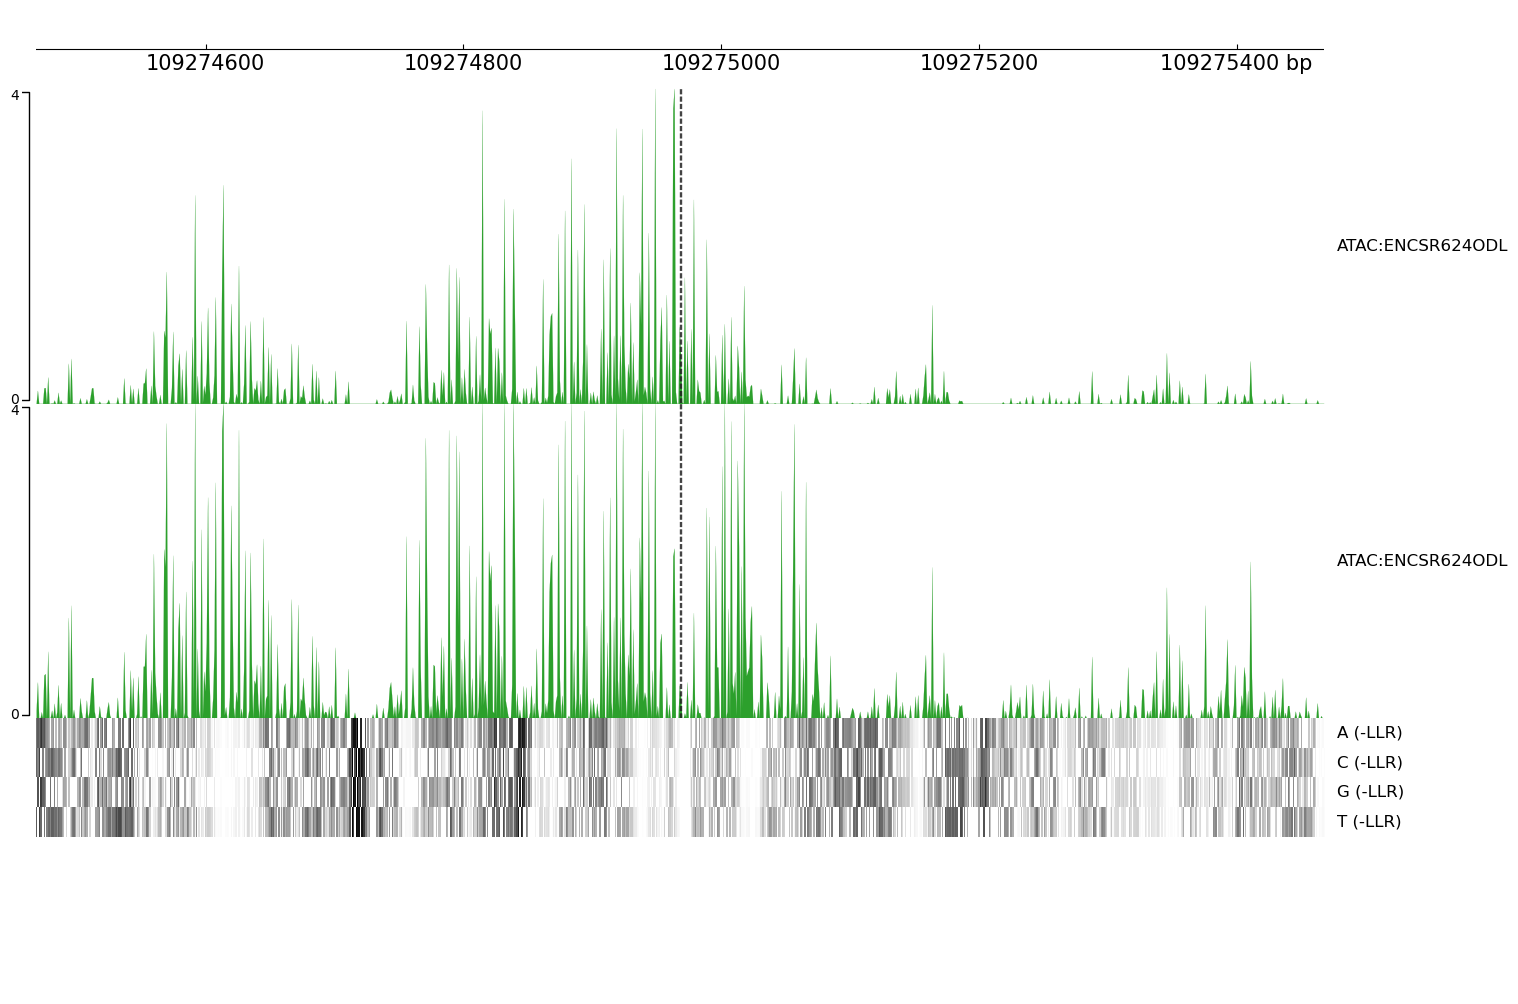

In [67]:
# Now plot the LLRs on top of ATAC experiments
atac_tracks = [
    variant_results[f"ATAC:{acc}"]["predictions"][condition][f"ATAC:{acc}"].get_coolbox_representation(
        add_xaxis=False,
        add_vlines=False,
    )
    + Vlines(f"{chrom}:{position}")    # add vline for variant site
    for acc in accessions
    for condition in ["reference", "alt_1"]
]

frame = XAxis()

for track in atac_tracks:
    frame += track

frame += gpn_track
frame += make_gene_track(gtf_path)

frame.plot("chr1:109_274_468-109_275_468") 

So GPN-star tells us that the variant is **not falling into a highly conserved region**, but there are some conserved regions close to the variant locus.

## Conclusion

This notebook demonstrates an integrative approach to genomics analysis by combining **Cherimoya** (specifically the **CATv1** atlas containing 1,518 per-experiment convolutional models covering 1,149 ENCODE DNase-seq and 369 ATAC-seq experiments) with **GPN-star**, a phylogeny-aware genomic language model.

Key takeaways from the analysis include:
* **Experiment-Specific Variation:** Because Cherimoya models are trained per experiment rather than pooled by biosample, validation metrics like `profile_pearson` and `count_pearson` vary across the atlas. Cycling through the four K562 ATAC models highlights subtle differences in the predicted profiles, showing the value of inspecting specific experimental tracks.
* **Genomic Visualization:** Using tools like **coolbox** allows seamless multi-track visualization alongside standard genomic annotations (such as Gencode GTF files), enabling researchers to visually inspect regional accessibility differences.
* **Variant Effect Prediction:** The analysis of the *SORT1* locus variant (*rs12740374*) illustrates how fine-grained sequence models can capture functional impacts, such as altered chromatin accessibility associated with differential gene expression, at specific genomic coordinates.
* **Evolutionary Context:** Overlaying GPN-star LLRs on the Cherimoya predictions places the variant in the context of sequence conservation, complementing the accessibility-based view.

**Acknowledgments:** We are grateful to **Yun Song** and **Chengzhong Ye** for their help in integrating GPN-star, and to **Jacob Schreiber** for developing and integrating Cherimoya into Chorus.